# Logistic regression

Pass or fail from hours studied. Batch gradient descent, no classes.

In [8]:
import numpy as np
import pandas as pd

df = pd.DataFrame({
    "student": ["A", "B", "C", "D"],
    "x": [1.0, 2.0, 3.0, 4.0],
    "y": [0.0, 0.0, 1.0, 1.0],
})
x = df["x"].to_numpy()
y = df["y"].to_numpy()
df

,student,x,y
0,A,1.0,0.0
1,B,2.0,0.0
2,C,3.0,1.0
3,D,4.0,1.0


In [9]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def bce(y, yhat):
    return -(y * np.log(yhat) + (1 - y) * np.log(1 - yhat))

Start at `w = 0`, `b = 0`. Then `z = 0` and every prediction is `0.5`.

In [10]:
w, b = 0.0, 0.0
yhat = sigmoid(w * x + b)
loss = bce(y, yhat)
J = loss.mean()

print(df.assign(yhat=yhat, loss=loss).round(4).to_string(index=False))
print(f"J = {J:.4f}")

student   x   y  yhat   loss
      A 1.0 0.0   0.5 0.6931
      B 2.0 0.0   0.5 0.6931
      C 3.0 1.0   0.5 0.6931
      D 4.0 1.0   0.5 0.6931
J = 0.6931


In [11]:
dw = ((yhat - y) * x).mean()
db = (yhat - y).mean()

grad = pd.DataFrame({
    "student": df["student"],
    "x": x,
    "y": y,
    "yhat - y": yhat - y,
    "(yhat - y) * x": (yhat - y) * x,
})
print(grad.round(4).to_string(index=False))
print(f"dJ/dw = {dw:.4f}")
print(f"dJ/db = {db:.4f}")

student   x   y  yhat - y  (yhat - y) * x
      A 1.0 0.0       0.5             0.5
      B 2.0 0.0       0.5             1.0
      C 3.0 1.0      -0.5            -1.5
      D 4.0 1.0      -0.5            -2.0
dJ/dw = -0.5000
dJ/db = 0.0000


One gradient descent step with learning rate `0.1`.

In [12]:
alpha = 0.1
w = w - alpha * dw
b = b - alpha * db
print(f"w = {w:.4f}, b = {b:.4f}")

yhat = sigmoid(w * x + b)
loss = bce(y, yhat)
J = loss.mean()
print(df.assign(yhat=yhat, loss=loss).round(4).to_string(index=False))
print(f"J = {J:.4f}")

w = 0.0500, b = 0.0000
student   x   y   yhat   loss
      A 1.0 0.0 0.5125 0.7185
      B 2.0 0.0 0.5250 0.7444
      C 3.0 1.0 0.5374 0.6210
      D 4.0 1.0 0.5498 0.5981
J = 0.6705


Same first step from `w = 0`, where `dJ/dw = -0.5`. Only the step size changes.

In [13]:
alphas = [0.001, 0.01, 0.1, 1.0]
w_new = [0 - a * (-0.5) for a in alphas]
pd.DataFrame({"alpha": alphas, "w_new": w_new})

,alpha,w_new
0,0.001,0.0005
1,0.010,0.0050
2,0.100,0.0500
3,1.000,0.5000


One epoch is one pass over all 4 rows. With batch gradient descent, that is one parameter update.

In [14]:
w, b = 0.0, 0.0
rows = []
for epoch in range(1, 11):
    yhat = sigmoid(w * x + b)
    J = bce(y, yhat).mean()
    dw = ((yhat - y) * x).mean()
    db = (yhat - y).mean()
    w -= alpha * dw
    b -= alpha * db
    rows.append({"epoch": epoch, "J": J, "w": w, "b": b})

history = pd.DataFrame(rows)
print(history.round(4).to_string(index=False))

yhat = sigmoid(w * x + b)
pred = df.assign(yhat=yhat, pred=(yhat >= 0.5).astype(int))
print(pred.round(4).to_string(index=False))

 epoch      J      w       b
     1 0.6931 0.0500  0.0000
     2 0.6705 0.0906 -0.0031
     3 0.6553 0.1240 -0.0087
     4 0.6448 0.1516 -0.0161
     5 0.6372 0.1747 -0.0250
     6 0.6314 0.1944 -0.0351
     7 0.6268 0.2112 -0.0460
     8 0.6229 0.2259 -0.0577
     9 0.6195 0.2387 -0.0699
    10 0.6164 0.2502 -0.0826
student   x   y   yhat  pred
      A 1.0 0.0 0.5418     1
      B 2.0 0.0 0.6029     1
      C 3.0 1.0 0.6610     1
      D 4.0 1.0 0.7146     1


# Plots

Curves for the values computed above. Run the logistic regression cells first.

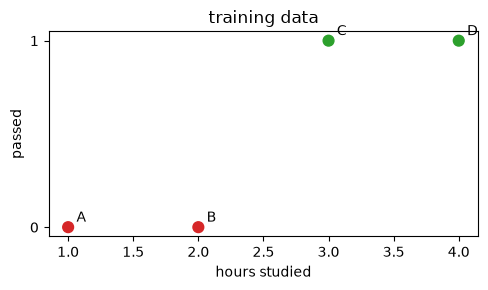

In [15]:
import matplotlib.pyplot as plt

xs = np.linspace(0, 5, 200)
colors = np.where(y == 1, "tab:green", "tab:red")

fig, ax = plt.subplots(figsize=(5, 3))
ax.scatter(x, y, c=colors, s=60, zorder=3)
for name, xi, yi in zip(df["student"], x, y):
    ax.annotate(name, (xi, yi), textcoords="offset points", xytext=(6, 4))
ax.set_yticks([0, 1])
ax.set_xlabel("hours studied")
ax.set_ylabel("passed")
ax.set_title("training data")
plt.tight_layout()
plt.show()

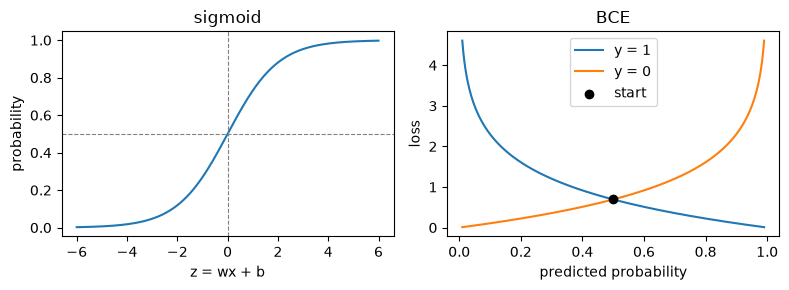

In [16]:
z = np.linspace(-6, 6, 300)
p = np.linspace(0.01, 0.99, 300)

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].plot(z, sigmoid(z))
axes[0].axhline(0.5, color="gray", ls="--", lw=0.8)
axes[0].axvline(0, color="gray", ls="--", lw=0.8)
axes[0].set_xlabel("z = wx + b")
axes[0].set_ylabel("probability")
axes[0].set_title("sigmoid")

axes[1].plot(p, bce(np.ones_like(p), p), label="y = 1")
axes[1].plot(p, bce(np.zeros_like(p), p), label="y = 0")
axes[1].scatter([0.5], [-np.log(0.5)], color="black", zorder=3, label="start")
axes[1].set_xlabel("predicted probability")
axes[1].set_ylabel("loss")
axes[1].set_title("BCE")
axes[1].legend()
plt.tight_layout()
plt.show()

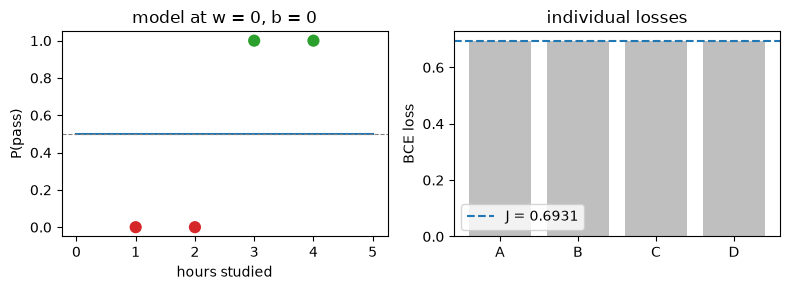

In [17]:
yhat0 = sigmoid(np.zeros_like(x))
loss0 = bce(y, yhat0)

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].scatter(x, y, c=colors, s=60, zorder=3)
axes[0].plot(xs, np.full_like(xs, 0.5), color="tab:blue")
axes[0].axhline(0.5, color="gray", ls="--", lw=0.8)
axes[0].set_ylim(-0.05, 1.05)
axes[0].set_xlabel("hours studied")
axes[0].set_ylabel("P(pass)")
axes[0].set_title("model at w = 0, b = 0")

axes[1].bar(df["student"], loss0, color="0.75")
axes[1].axhline(loss0.mean(), color="tab:blue", ls="--", label=f"J = {loss0.mean():.4f}")
axes[1].set_ylabel("BCE loss")
axes[1].set_title("individual losses")
axes[1].legend()
plt.tight_layout()
plt.show()

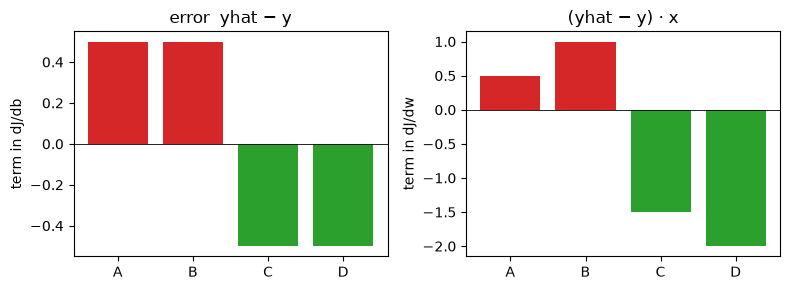

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].bar(grad["student"], grad["yhat - y"], color=colors)
axes[0].axhline(0, color="black", lw=0.6)
axes[0].set_title("error  yhat − y")
axes[0].set_ylabel("term in dJ/db")

axes[1].bar(grad["student"], grad["(yhat - y) * x"], color=colors)
axes[1].axhline(0, color="black", lw=0.6)
axes[1].set_title("(yhat − y) · x")
axes[1].set_ylabel("term in dJ/dw")
plt.tight_layout()
plt.show()

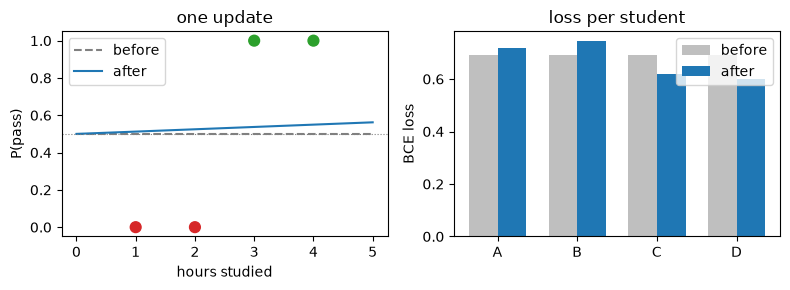

In [19]:
step = history.iloc[0]
loss0 = bce(y, np.full_like(y, 0.5))
loss1 = bce(y, sigmoid(step["w"] * x + step["b"]))

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].scatter(x, y, c=colors, s=60, zorder=3)
axes[0].plot(xs, np.full_like(xs, 0.5), ls="--", color="gray", label="before")
axes[0].plot(xs, sigmoid(step["w"] * xs + step["b"]), color="tab:blue", label="after")
axes[0].axhline(0.5, color="gray", ls=":", lw=0.8)
axes[0].set_ylim(-0.05, 1.05)
axes[0].set_xlabel("hours studied")
axes[0].set_ylabel("P(pass)")
axes[0].set_title("one update")
axes[0].legend()

idx = np.arange(len(df))
axes[1].bar(idx - 0.18, loss0, width=0.36, label="before", color="0.75")
axes[1].bar(idx + 0.18, loss1, width=0.36, label="after", color="tab:blue")
axes[1].set_xticks(idx)
axes[1].set_xticklabels(df["student"])
axes[1].set_ylabel("BCE loss")
axes[1].set_title("loss per student")
axes[1].legend()
plt.tight_layout()
plt.show()

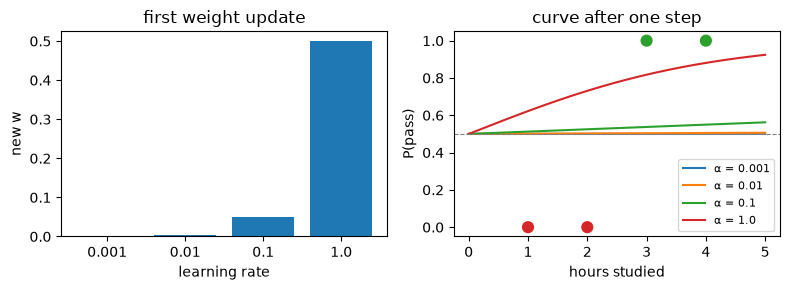

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].bar([str(a) for a in alphas], w_new, color="tab:blue")
axes[0].set_xlabel("learning rate")
axes[0].set_ylabel("new w")
axes[0].set_title("first weight update")

axes[1].scatter(x, y, c=colors, s=60, zorder=3)
for a, wi in zip(alphas, w_new):
    axes[1].plot(xs, sigmoid(wi * xs), label=f"α = {a}")
axes[1].axhline(0.5, color="gray", ls="--", lw=0.8)
axes[1].set_ylim(-0.05, 1.05)
axes[1].set_xlabel("hours studied")
axes[1].set_ylabel("P(pass)")
axes[1].set_title("curve after one step")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

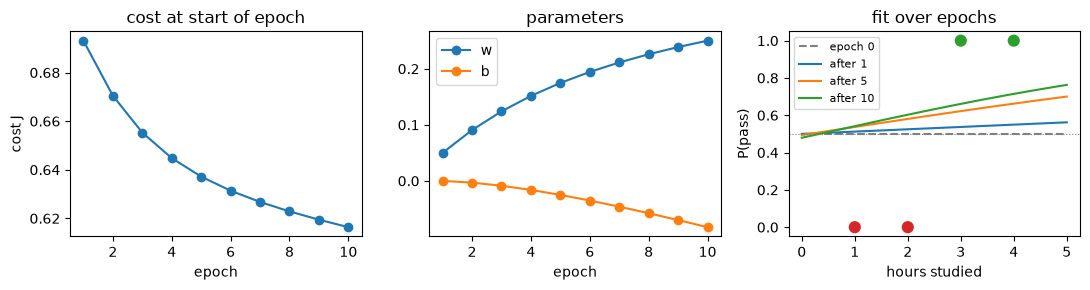

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
axes[0].plot(history["epoch"], history["J"], marker="o")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("cost J")
axes[0].set_title("cost at start of epoch")

axes[1].plot(history["epoch"], history["w"], marker="o", label="w")
axes[1].plot(history["epoch"], history["b"], marker="o", label="b")
axes[1].set_xlabel("epoch")
axes[1].set_title("parameters")
axes[1].legend()

axes[2].scatter(x, y, c=colors, s=60, zorder=3)
axes[2].plot(xs, np.full_like(xs, 0.5), ls="--", color="gray", label="epoch 0")
for ep in (1, 5, 10):
    row = history.loc[history["epoch"] == ep].iloc[0]
    axes[2].plot(xs, sigmoid(row["w"] * xs + row["b"]), label=f"after {ep}")
axes[2].axhline(0.5, color="gray", ls=":", lw=0.8)
axes[2].set_ylim(-0.05, 1.05)
axes[2].set_xlabel("hours studied")
axes[2].set_ylabel("P(pass)")
axes[2].set_title("fit over epochs")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()